# 01 – Exploratory Data Analysis
RetailGenius churn – E-Commerce dataset (Kaggle). Findings here drive `churn.data` (cleaning) and `churn.features` (feature engineering).

In [1]:
import sys; sys.path.insert(0, '../src')
import pandas as pd, matplotlib.pyplot as plt
from churn import config
from churn.data import load_raw
df = load_raw(config.RAW_DATA_PATH)
df.shape

(5630, 20)

In [2]:
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


## Target balance

In [3]:
df['Churn'].value_counts(normalize=True).round(3)

Churn
0    0.832
1    0.168
Name: proportion, dtype: float64

## Missing values

In [4]:
df.isna().sum()[lambda s: s > 0].sort_values(ascending=False)

DaySinceLastOrder              307
OrderAmountHikeFromlastYear    265
Tenure                         264
OrderCount                     258
CouponUsed                     256
HourSpendOnApp                 255
WarehouseToHome                251
dtype: int64

## Inconsistent category labels (fixed in `churn.data.CATEGORY_FIXES`)

In [5]:
for col in config.CATEGORICAL_FEATURES:
    print(col, df[col].value_counts().to_dict())

PreferredLoginDevice {'Mobile Phone': 2765, 'Computer': 1634, 'Phone': 1231}
PreferredPaymentMode {'Debit Card': 2314, 'Credit Card': 1501, 'E wallet': 614, 'UPI': 414, 'COD': 365, 'CC': 273, 'Cash on Delivery': 149}
Gender {'Male': 3384, 'Female': 2246}
PreferedOrderCat {'Laptop & Accessory': 2050, 'Mobile Phone': 1271, 'Fashion': 826, 'Mobile': 809, 'Grocery': 410, 'Others': 264}
MaritalStatus {'Married': 2986, 'Single': 1796, 'Divorced': 848}


## Churn rate by key drivers

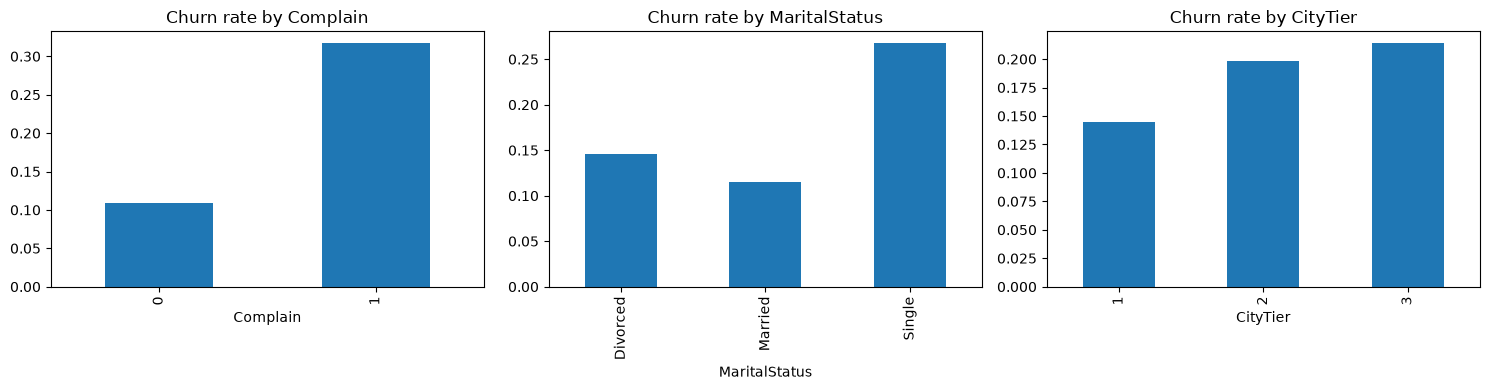

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Complain', 'MaritalStatus', 'CityTier']):
    df.groupby(col)['Churn'].mean().plot.bar(ax=ax, title=f'Churn rate by {col}')
plt.tight_layout()

In [7]:
df.groupby('Churn')[['Tenure', 'CashbackAmount', 'DaySinceLastOrder', 'NumberOfAddress']].median()

,Tenure,CashbackAmount,DaySinceLastOrder,NumberOfAddress
Churn,,,,
0,10.0,166.115,4.0,3.0
1,1.0,149.660,2.0,3.0


## Numeric correlations with churn

In [8]:
df.select_dtypes('number').corr()['Churn'].drop(['Churn','CustomerID']).sort_values()

Tenure                        -0.349408
DaySinceLastOrder             -0.160757
CashbackAmount                -0.154118
OrderCount                    -0.028697
OrderAmountHikeFromlastYear   -0.010058
CouponUsed                    -0.008264
HourSpendOnApp                 0.018675
NumberOfAddress                0.043931
WarehouseToHome                0.076630
CityTier                       0.084703
SatisfactionScore              0.105481
NumberOfDeviceRegistered       0.107939
Complain                       0.250188
Name: Churn, dtype: float64